In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv('/content/historical_sales.csv.csv', encoding='latin1')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.shape

(9994, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [7]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [8]:
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())

In [10]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

In [12]:
df = df.sort_values('Order Date')

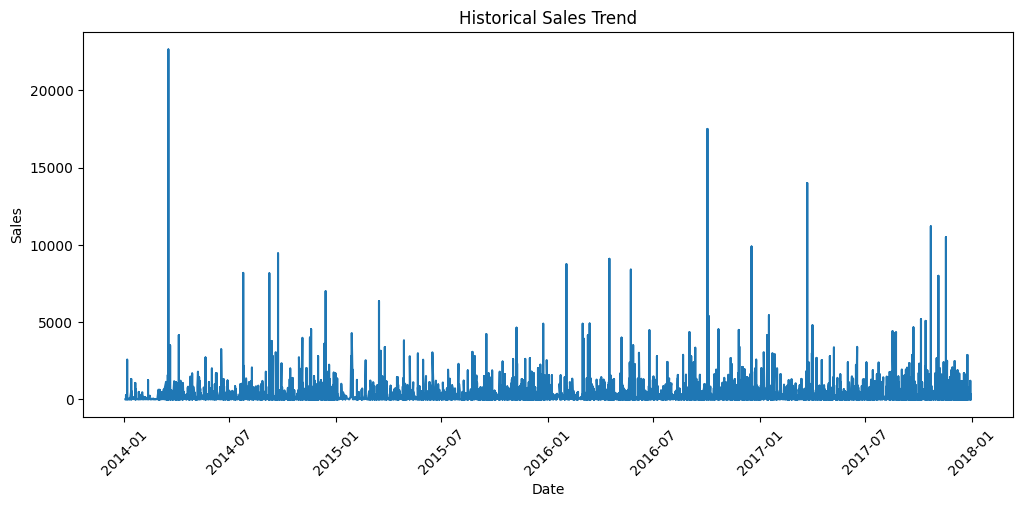

In [14]:
plt.figure(figsize=(12,5))

plt.plot(df['Order Date'], df['Sales'])

plt.xlabel('Date')
plt.ylabel('Sales')
plt.title('Historical Sales Trend')

plt.xticks(rotation=45)
plt.show()

In [16]:
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Day'] = df['Order Date'].dt.day

In [17]:
df['Time_Index'] = np.arange(len(df))

In [18]:
X = df[['Time_Index']]
y = df['Sales']

In [19]:
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [20]:
model = LinearRegression()

In [21]:
model.fit(X_train, y_train)

LinearRegression()

In [22]:
y_pred = model.predict(X_test)

In [23]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 259.4977602559918


In [24]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 585.6894342877811


In [25]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: -0.00011320235820044822


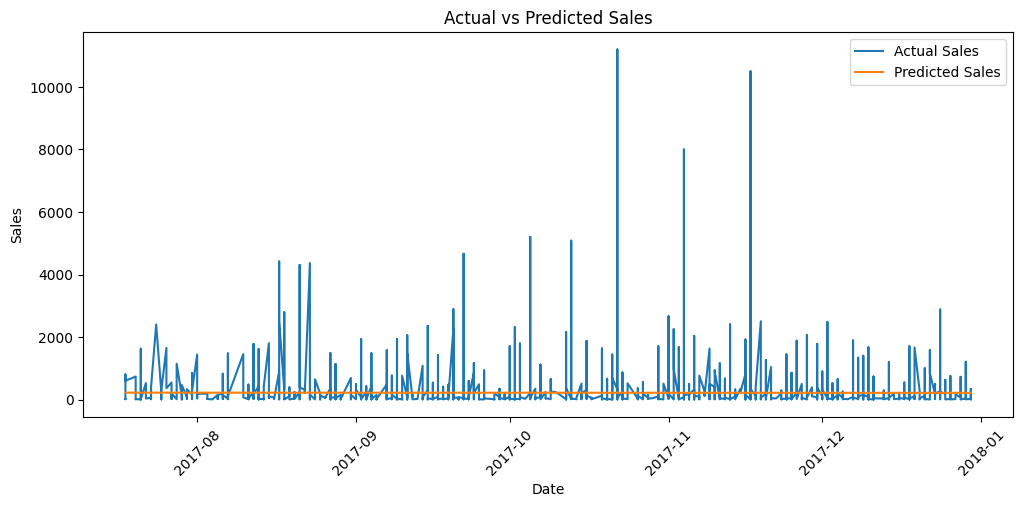

In [27]:
plt.figure(figsize=(12,5))

plt.plot(df['Order Date'].iloc[split:], y_test, label='Actual Sales')
plt.plot(df['Order Date'].iloc[split:], y_pred, label='Predicted Sales')

plt.xlabel('Date')
plt.ylabel('Sales')
plt.title('Actual vs Predicted Sales')

plt.legend()
plt.xticks(rotation=45)

plt.show()

In [28]:
last_index = df['Time_Index'].max()

In [29]:
future_indices = np.arange(
    last_index + 1,
    last_index + 7
).reshape(-1, 1)

In [30]:
future_predictions = model.predict(future_indices)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [31]:
future_predictions

array([214.68016255, 214.67746635, 214.67477016, 214.67207397,
       214.66937778, 214.66668159])

In [34]:
future_dates = pd.date_range(
    start=df['Order Date'].max() + pd.DateOffset(months=1),
    periods=6,
    freq='MS'
)

In [35]:
future_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Sales': future_predictions
})

future_df

,Date,Predicted_Sales
0,2018-02-01,214.680163
1,2018-03-01,214.677466
2,2018-04-01,214.674770
3,2018-05-01,214.672074
4,2018-06-01,214.669378
5,2018-07-01,214.666682


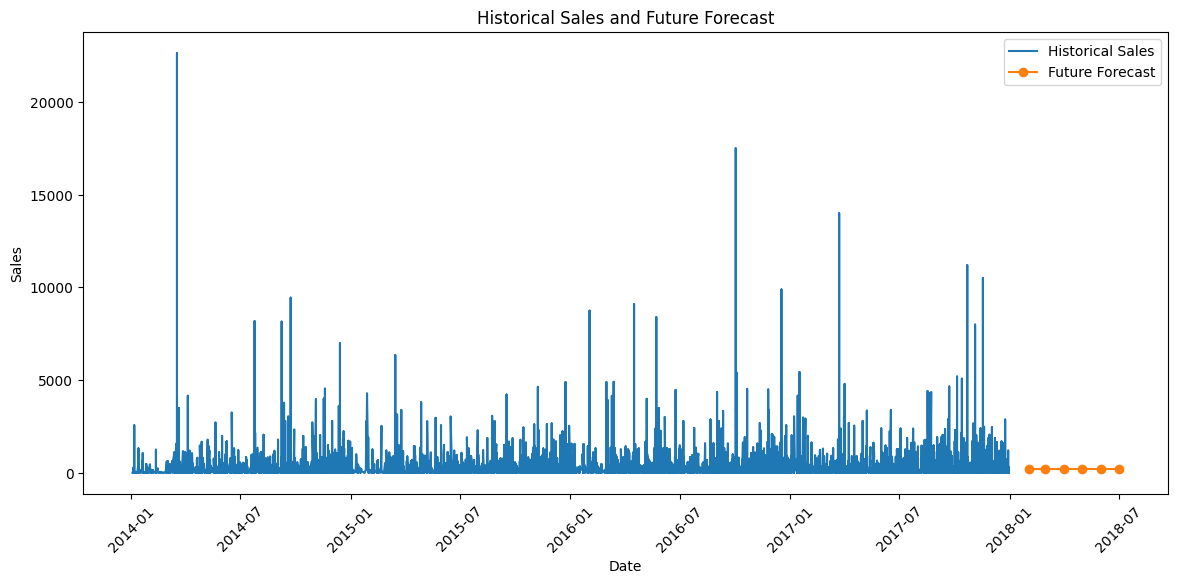

In [37]:
plt.figure(figsize=(14,6))

plt.plot(
    df['Order Date'],
    df['Sales'],
    label='Historical Sales'
)

plt.plot(
    future_df['Date'],
    future_df['Predicted_Sales'],
    marker='o',
    label='Future Forecast'
)

plt.xlabel('Date')
plt.ylabel('Sales')
plt.title('Historical Sales and Future Forecast')

plt.legend()
plt.xticks(rotation=45)

plt.show()

In [38]:
future_df.to_csv(
    '/content/future_sales_predictions.csv',
    index=False
)